## Graph generation

In [2]:
def generate_erdos_graph(vertices=5, probability=0.5, seed=67, output=False):
    import networkx as nx
    import matplotlib.pyplot as plt
    
    G = nx.erdos_renyi_graph(vertices, probability, seed=seed)
    
    vertices = G.nodes()
    edges = G.edges()

    if output:
        print("Nodes:", vertices)
        print("Edges:", edges)
        print("Number of edges:", G.number_of_edges())
        
        pos = nx.spring_layout(G, seed=seed)
        nx.draw_networkx_nodes(G, pos, node_size=700, node_color="skyblue")
        nx.draw_networkx_edges(G, pos, width=2, edge_color="gray")
        nx.draw_networkx_labels(G, pos, font_size=12, font_family="sans-serif")
        
        plt.title("Visualisation of graph")
        plt.axis("off")
        plt.show()
    return G

Nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Edges: [(0, 3), (0, 4), (0, 8), (1, 4), (1, 5), (1, 6), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (3, 4), (3, 8), (3, 9), (4, 5), (4, 6), (5, 6), (7, 8)]
Number of edges: 19


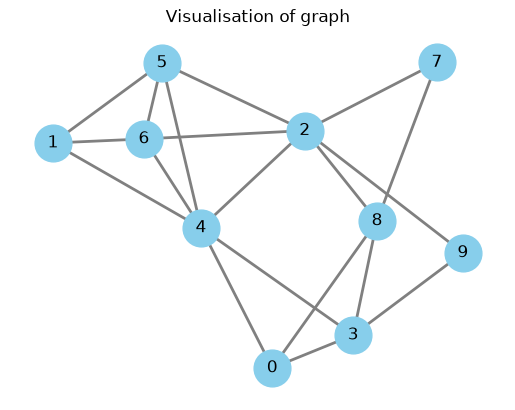

In [3]:
generate_erdos_graph(vertices=10, probability=0.5, seed=2, output=True)

In [85]:
def generate_constant_graph(vertices=6, degree=3, output=False, seed=67):
    import networkx as nx
    import matplotlib.pyplot as plt

    G = nx.random_regular_graph(d=degree, n=vertices, seed=seed)
    
    print("Is regular:", nx.is_regular(G))
    print("Node degrees:", dict(G.degree()))

    vertices = G.nodes()
    edges = G.edges()

    if output:
        print("Nodes:", vertices)
        print("Edges:", edges)
        print("Number of edges:", G.number_of_edges())
        
        pos = nx.spring_layout(G, seed=seed)
        nx.draw_networkx_nodes(G, pos, node_size=700, node_color="skyblue")
        nx.draw_networkx_edges(G, pos, width=2, edge_color="gray")
        nx.draw_networkx_labels(G, pos, font_size=12, font_family="sans-serif")
        
        plt.title("Visualisation of graph")
        plt.axis("off")
        plt.show()
    return G

Is regular: True
Node degrees: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3}
Nodes: [0, 1, 2, 3, 4, 5, 6, 7]
Edges: [(0, 7), (0, 3), (0, 5), (1, 2), (1, 7), (1, 6), (2, 4), (2, 7), (3, 4), (3, 6), (4, 5), (5, 6)]
Number of edges: 12


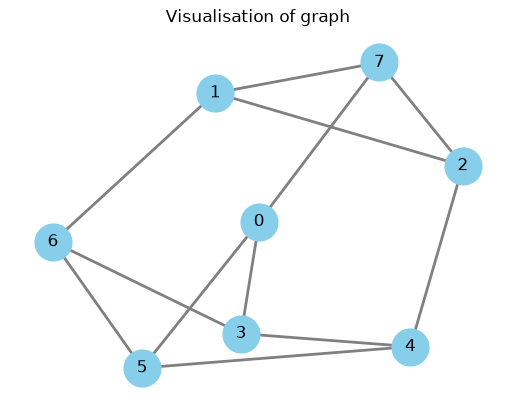

In [5]:
generate_constant_graph(8, 3, True, 110)

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

def generate_cycle_with_chords(vertices=8, output=False):
    G = nx.cycle_graph(vertices)
    num_chords = vertices // 4
    step = vertices // (2 * num_chords)
    
    for k in range(num_chords):
        u = k * step
        v = (u + vertices // 2) % vertices
        G.add_edge(u, v, type='chord')
    
    print("Is regular:", nx.is_regular(G))
    print("Node degrees:", dict(G.degree()))

    vertices_list = G.nodes()
    edges_list = G.edges()

    if output:
        print("Nodes:", vertices_list)
        print("Edges:", edges_list)
        print("Number of edges:", G.number_of_edges())
        
        pos = nx.circular_layout(G)
        
        cycle_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('type') != 'chord']
        chord_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('type') == 'chord']
        
        plt.figure(figsize=(6, 6))
        nx.draw_networkx_nodes(G, pos, node_size=700, node_color="skyblue")
        nx.draw_networkx_labels(G, pos, font_size=12, font_family="sans-serif")
        
        nx.draw_networkx_edges(G, pos, edgelist=cycle_edges, width=2, edge_color="gray")
        nx.draw_networkx_edges(G, pos, edgelist=chord_edges, width=2, edge_color="red", style="dashed")
        
        plt.title("Visualisation of graph")
        plt.axis("off")
        plt.show()
    return G

Is regular: False
Node degrees: {0: 3, 1: 2, 2: 3, 3: 2, 4: 3, 5: 2, 6: 3, 7: 2}
Nodes: [0, 1, 2, 3, 4, 5, 6, 7]
Edges: [(0, 1), (0, 7), (0, 4), (1, 2), (2, 3), (2, 6), (3, 4), (4, 5), (5, 6), (6, 7)]
Number of edges: 10


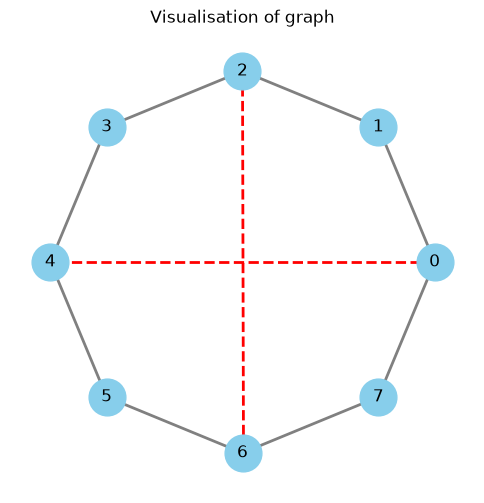

In [7]:
G = generate_cycle_with_chords(8, True)

## Greedy algorithm

In [8]:
def calculate_cut_value(G, partition):
    total = 0

    for u, v, data in G.edges(data=True):
        if partition[u] != partition[v]:
            total -= data.get("weight", 1.0)
        else:
            total += data.get("weight", 1.0)

    return total

In [83]:
import networkx as nx
import matplotlib.pyplot as plt

def greedy_max_cut(G):
    print(len(G.edges()))
    partition = {}
    for vertex in G.nodes:
        a_neighbours = 0
        b_neighbours = 0
        
        for neighbor in G.neighbors(vertex):
            if neighbor in partition:
                weight = G[vertex][neighbor].get("weight", 1.0)
                if partition[neighbor] == 0:
                    a_neighbours += weight
                elif partition[neighbor] == 1:
                    b_neighbours += weight
        
        if a_neighbours > b_neighbours:
            partition[vertex] = 1
        elif b_neighbours > a_neighbours:
            partition[vertex] = 0
        else:
            count_A = sum(1 for v in partition if partition[v] == 0)
            count_B = sum(1 for v in partition if partition[v] == 1)
            partition[vertex] = 0 if count_A <= count_B else 1
            
    total_score = calculate_cut_value(G, partition)
    
    subset_A = [node for node, part in partition.items() if part == 0]
    subset_B = [node for node, part in partition.items() if part == 1]
    
    print(f"Set A: {subset_A}")
    print(f"Set B: {subset_B}")
    print("Score = ", total_score)
    
    node_colors = []
    for node in G.nodes:
        if partition[node] == 0:
            node_colors.append("skyblue")
        else:
            node_colors.append("tomato")
            
    pos = nx.spring_layout(G, seed=42)
    
    plt.figure(figsize=(6, 5))
    nx.draw(
        G, 
        pos, 
        with_labels=True, 
        node_color=node_colors, 
        node_size=800, 
        font_weight='bold', 
        edge_color='gray'
    )
    
    plt.title(f"Max-Cut \nScore : {total_score}")
    plt.show()
    
    return total_score, subset_A, subset_B

## QAOA

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

def solve_max_cut_qaoa(G, p=2, shots=2048):
    nodes = list(G.nodes())
    index = {v: i for i, v in enumerate(nodes)}
    edges = [
        (index[u], index[v], d.get("weight", 1))
        for u, v, d in G.edges(data=True)
    ]
    backend = AerSimulator()

    def run_qaoa(params):
        gammas, betas = params[:p], params[p:]
        qc = QuantumCircuit(len(nodes), len(nodes))
        qc.h(range(len(nodes)))

        for gamma, beta in zip(gammas, betas):
            for u, v, w in edges:
                qc.rzz(2 * gamma * w, u, v)
            for q in range(len(nodes)):
                qc.rx(2 * beta, q)

        qc.measure(range(len(nodes)), range(len(nodes)))
        return backend.run(qc, shots=shots).result().get_counts()

    def score(bits):
        bits = bits[::-1]
        return sum(
            -w if bits[u] != bits[v] else w
            for u, v, w in edges
        )
    def objective(params):
        counts = run_qaoa(params)
        total = sum(counts.values())
        return sum(
            score(bits) * count
            for bits, count in counts.items()
        ) / total

    initial = np.random.uniform(0, 2 * np.pi, 2 * p)
    result = minimize(objective, initial, method="COBYLA")

    counts = run_qaoa(result.x)
    best = min(counts, key=score)

    best_ordered = best[::-1]
    partition = {
        nodes[i]: int(best_ordered[i])
        for i in range(len(nodes))
    }

    # Visualize the partition
    pos = nx.spring_layout(G, seed=42)

    colors = [
        "cornflowerblue" if partition[node] == 0 else "tomato"
        for node in G.nodes()
    ]

    nx.draw(
        G, pos,
        with_labels=True,
        node_color=colors,
        node_size=800,
        font_weight="bold",
        edge_color="gray",
        width=1.5
    )

    plt.title("QAOA Max-Cut")
    plt.show()
    best = min(counts, key=score)
    print("QAOA score:", score(best))
    return partition, score(best)

## Experiment (example run)

Is regular: True
Node degrees: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 3}
Nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Edges: [(0, 14), (0, 7), (0, 15), (1, 15), (1, 4), (1, 7), (2, 11), (2, 9), (2, 6), (3, 13), (3, 6), (3, 14), (4, 7), (4, 10), (5, 13), (5, 9), (5, 8), (6, 8), (8, 12), (9, 12), (10, 15), (10, 11), (11, 12), (13, 14)]
Number of edges: 24


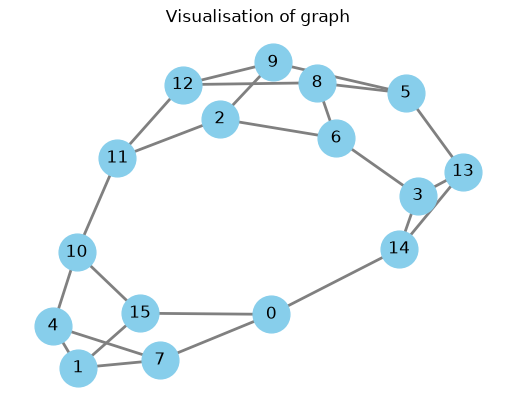

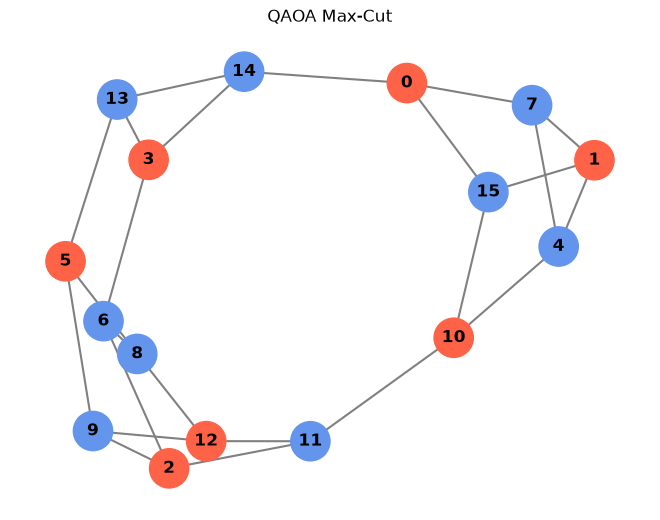

QAOA score: -18


({0: 1,
  1: 1,
  2: 1,
  3: 1,
  4: 0,
  5: 1,
  6: 0,
  7: 0,
  8: 0,
  9: 0,
  10: 1,
  11: 0,
  12: 1,
  13: 0,
  14: 0,
  15: 0},
 -18)

In [102]:
graph = generate_constant_graph(16, 3, output=True, seed=1259)
solve_max_cut_qaoa(graph, p=2, shots=2048)